# Chaînes 14 — P, C, T et CPT

Chapitre 53 du compendium *Chain Theory* (Wissner-Gross, 2026, preprint non relu), sections 59 à 61 — le compendium numérote ce chapitre « 4-6, 3-6 in the module numbering (sections 59 to 61) » (p. 159). Trois résultats : le **Théorème 59.1** (standing: a conditional theorem) — la parité lue comme l'élément impropre, absente du groupe de symétrie des enregistrements ; l'**Open result 60.1** (standing: an open result) — les lois discrètes comme réflexions de Weyl à la coupure, ouvert à sa ligne de parting ; et le **Théorème 61.1** (standing: theorem) — trois involutions (échange des bouts, renversement de chaîne, renversement de lecture) dont le produit est l'identité sur les comptes, nommé par correspondance avec le théorème de Lüders-Pauli [102, 103].

Le patron de la série tient : **Mesuré** ce que nos fractions rejouent, **Cité** toute la chaîne dérivative du source, **Ouvert** ce qu'il ne prouve pas.

## Le cadre : des symétries continues aux discrètes

« The next chapter turns from the continuous symmetries to the discrete ones » (p. 159) — la promesse tenue du chapitre précédent. Le geste : le **groupe réseau** des trois directions dérivées ($48$ matrices de permutation signées, carrefour avec l'éq. 73 de Chaînes-08) contre le **groupe d'identification** au bout qubit ($32$ monomiales à phases racines quatrièmes, carrefour avec Chaînes-10) ; ce que l'un induit sur l'autre décide si la parité — l'élément impropre — est une symétrie des enregistrements. Puis les lois discrètes relues comme **réflexions de Weyl à la coupure**, et les trois involutions dont le produit rend CPT exact sur les comptes.

Les trois noms de la littérature : la parité est l'inversion $x \mapsto -x$, violée par l'interaction faible [97] ; la conjugaison de charge porte une particule à son antiparticule ; T est antiunitaire, et CPT une symétrie exacte de toute théorie quantique des champs locale et invariante de Lorentz [98-100] ; la violation de CP entre par une phase de la matrice de mélange [58]. La correspondence est **par nom** (p. 160).

In [1]:
# Arithmetique exacte : un complexe est une paire de Fractions (re, im).
from fractions import Fraction as F
from itertools import permutations, product

def cadd(a, b): return (a[0] + b[0], a[1] + b[1])
def csub(a, b): return (a[0] - b[0], a[1] - b[1])
def cmul(a, b): return (a[0] * b[0] - a[1] * b[1], a[0] * b[1] + a[1] * b[0])
def cscale(q, a): return (q * a[0], q * a[1])
def cconj(a): return (a[0], -a[1])
Z, U, CI = (F(0), F(0)), (F(1), F(0)), (F(0), F(1))
POW4 = [U, CI, (-F(1), F(0)), (F(0), -F(1))]   # 1, i, -1, -i : les phases racines quatriemes

def cstr(a):
    re, im = a
    if re == 0 and im == 0: return "0"
    parts = []
    if re != 0: parts.append(str(re))
    if im != 0:
        sign = "-" if im < 0 else ("+" if parts else "")
        mag = abs(im)
        parts.append(sign + ("" if mag == 1 else str(mag)) + "i")
    return "".join(parts)

def meye(n): return [[(F(int(i == j)), F(0)) for j in range(n)] for i in range(n)]
def mzeros(n): return [[Z for _ in range(n)] for _ in range(n)]
def madd(A, B): return [[cadd(A[i][j], B[i][j]) for j in range(len(A))] for i in range(len(A))]
def msub(A, B): return [[csub(A[i][j], B[i][j]) for j in range(len(A))] for i in range(len(A))]
def mmul(A, B):
    n, m, K = len(A), len(B[0]), len(B)
    out = [[Z for _ in range(m)] for _ in range(n)]
    for i in range(n):
        for j in range(m):
            s = Z
            for t in range(K):
                s = cadd(s, cmul(A[i][t], B[t][j]))
            out[i][j] = s
    return out
def mscale(q, A): return [[cscale(q, A[i][j]) for j in range(len(A))] for i in range(len(A))]
def mT(A): return [[A[j][i] for j in range(len(A))] for i in range(len(A))]
def mdag(A): return [[cconj(A[j][i]) for j in range(len(A))] for i in range(len(A))]
def meq(A, B): return A == B
def mnul(A): return all(A[i][j] == Z for i in range(len(A)) for j in range(len(A)))
def _tr(A):
    s = Z
    for i in range(len(A)):
        s = cadd(s, A[i][i])
    return s
def kron(A, B):
    n, m, p, q = len(A), len(A[0]), len(B), len(B[0])
    return [[cmul(A[i // p][j // q], B[i % p][j % q]) for j in range(m * q)] for i in range(n * p)]
def mstr(A): return "[" + " ; ".join(", ".join(cstr(x) for x in row) for row in A) + "]"

# Les trois directions derivees au bout qubit : les lettres de Pauli sur Q(i).
sx = [[Z, U], [U, Z]]
sy = [[Z, (F(0), F(-1))], [(F(0), F(1)), Z]]
sz = [[U, Z], [Z, (-F(1), F(0))]]
DIRS3 = [sx, sy, sz]

def det3(M):
    # Determinant exact d'une 3x3 sur Q(i) : formule par permutations, signe par cycles.
    t = Z
    for p in permutations(range(3)):
        seen, cycles = [False] * 3, 0
        for i in range(3):
            if not seen[i]:
                cycles += 1
                j = i
                while not seen[j]:
                    seen[j] = True
                    j = p[j]
        sgn = (-1) ** (3 - cycles)
        term = U if sgn == 1 else (-F(1), F(0))
        for i in range(3):
            term = cmul(term, M[i][p[i]])
        t = cadd(t, term)
    return t

print("noyau Q(i) charge ; les phases racines quatriemes :", [cstr(x) for x in POW4])

noyau Q(i) charge ; les phases racines quatriemes : ['1', 'i', '-1', '-i']


## §59 — Théorème 59.1 : la parité comme l'élément impropre

« The lattice group of the three directions has forty-eight signed permutation matrices, half improper, while the identification group at the qubit end acts through eight proper ones and no identification unitary induces an improper element, so parity is not a symmetry of the records » (p. 159). L'éq. 90 d'abord : les **six permutations** des trois axes aux **huit tuples de signes** — le groupe réseau, $6 \cdot 8 = 48$, moitié propres moitié impropres au déterminant. C'est exactement l'objet de l'éq. 73 de Chaînes-08 : le carrefour est mesuré des deux côtés. Standing: a conditional theorem.

In [2]:
# Eq. 90 : le groupe reseau des trois directions -- six permutations x huit tuples de signes.
reseau = []
for perm in permutations(range(3)):
    for sg in product([1, -1], repeat=3):
        M = mzeros(3)
        for i in range(3):
            M[i][perm[i]] = U if sg[i] == 1 else (-F(1), F(0))
        reseau.append(M)
propres = [M for M in reseau if det3(M) == U]
impropres = [M for M in reseau if det3(M) == (-F(1), F(0))]
eq90_ok = (len(reseau) == 48 and len(propres) == 24 and len(impropres) == 24)
print("eq. 90 : |L| =", len(reseau), " #{det = +1} =", len(propres), " #{det = -1} =", len(impropres))
print("attendu (imprime p. 161) : 6 x 8 = 48, 24, 24  ->", eq90_ok)

eq. 90 : |L| = 48  #{det = +1} = 24  #{det = -1} = 24
attendu (imprime p. 161) : 6 x 8 = 48, 24, 24  -> True


### Lecture du résultat (le groupe réseau, éq. 90)

**L'éq. 90 est rejouée** : les $6 \times 8 = 48$ matrices de permutation signée, déterminant exact en fractions — **24 propres, 24 impropres**. La moitié impropre, c'est la porte par laquelle la parité entre : l'inversion $x \mapsto -x$ du nom de la littérature est $-I_3$ dans ce groupe, de déterminant $(-1)^3 = -1$, impropre. La question du théorème est alors : est-ce qu'une **transformation d'identification** au bout qubit — une monomiale unitaire — induit jamais un impropre ? L'éq. 91 y répond par l'énumération.

In [3]:
# Eq. 91 : le groupe d'identification au bout qubit -- 32 monomiales a phases racines quatriemes.
# 16 diagonales (a, b) + 16 antidiagonales, a et b dans {1, i, -1, -i}.  Carrefour Chaines-10.
identif = []
for a in POW4:
    for b in POW4:
        identif.append([[a, Z], [Z, b]])
for a in POW4:
    for b in POW4:
        identif.append([[Z, a], [b, Z]])
print("|G| monomiales :", len(identif), "(16 diagonales + 16 antidiagonales)")

def induite(M):
    # Action par conjugaison sur (sx, sy, sz) -> la matrice 3x3 de permutation signee induite.
    cols = []
    for S in DIRS3:
        img = mmul(mmul(M, S), mdag(M))
        col = None
        for k, T in enumerate(DIRS3):
            if meq(img, T):
                col = [U if i == k else Z for i in range(3)]
                break
            if meq(img, mscale(F(-1), T)):
                col = [(-F(1), F(0)) if i == k else Z for i in range(3)]
                break
        assert col is not None, "conjugaison hors de l'espace genere"
        cols.append(col)
    return [[cols[j][i] for j in range(3)] for i in range(3)]

images = [induite(M) for M in identif]   # listes non hachables -> listesparalleles
distinct = []
for P in images:
    if P not in distinct:
        distinct.append(P)
noyau = [M for M, P in zip(identif, images) if meq(P, meye(3))]
scalaires = all(meq(M, mscale(1, [[M[0][0], Z], [Z, M[0][0]]])) for M in noyau)
detplus = all(det3(P) == U for P in distinct)
impropres_atteints = sum(1 for P in images if P in impropres)
eq91_ok = (len(identif) == 32 and len(distinct) == 8 and detplus
           and len(noyau) == 4 and scalaires and impropres_atteints == 0)
print("eq. 91 : |im G| =", len(distinct), " det = +1 partout :", detplus)
print("   noyau :", len(noyau), "elements, tous scalaires :", scalaires,
      "->", [cstr(M[0][0]) for M in noyau])
print("   l'identite porte", len(noyau), "antecedents parmi les 32 (le noyau)")
print("   antecedents des 24 impropres :", impropres_atteints, "-> l'impropre n'a AUCUN antecedent")
print("attendu (imprime p. 160) : 32, 32/4 = 8, det +1, noyau 4 scalaires, 0  ->", eq91_ok)

|G| monomiales : 32 (16 diagonales + 16 antidiagonales)
eq. 91 : |im G| = 8  det = +1 partout : True
   noyau : 4 elements, tous scalaires : True -> ['1', 'i', '-1', '-i']
   l'identite porte 4 antecedents parmi les 32 (le noyau)
   antecedents des 24 impropres : 0 -> l'impropre n'a AUCUN antecedent
attendu (imprime p. 160) : 32, 32/4 = 8, det +1, noyau 4 scalaires, 0  -> True


### Lecture du résultat (l'éq. 91 — la parité hors symétrie)

**L'éq. 91 est rejouée entrée par entrée** : les $32$ monomiales — le même groupe que Chaînes-10 mesurait déjà ($2$ choix de colonnes $\times 4^2$ phases) — agissent par conjugaison sur les trois directions, et l'**image induite compte 8 éléments, tous de déterminant $+1$** : les huit rotations propres du réseau (l'ordre $32/4 = 8$ par Lagrange, le noyau des 4 phases scalaires $\{1, i, -1, -i\}$, chacune agissant trivialement). L'identité porte ses 4 antécédents — le plus petit cas travaillé « above » (p. 161) — et **chaque élément impropre en porte zéro** : aucune identification ne se lit comme une parité. C'est la conclusion du théorème : « parity is not a symmetry of the records » (p. 160) — la parité n'est pas une symétrie des enregistrements, au sens du compendium et sous ses prémisses.

In [4]:
# Contre-test imprime (p. 161) : adjoindre -I3 au groupe image -- la cloture <im, -I3>.
mI3 = (-F(1), F(0))
neg = lambda P: [[cmul(mI3, P[i][j]) for j in range(3)] for i in range(3)]
cloture = distinct + [neg(P) for P in distinct]
cloture_uniq = []
for P in cloture:
    if P not in cloture_uniq:
        cloture_uniq.append(P)
imp_cl = [P for P in cloture_uniq if det3(P) == (-F(1), F(0))]
moI3 = [[(-F(1), F(0)) if i == j else Z for j in range(3)] for i in range(3)]
sans_antecedent = not any(meq(P, moI3) for P in images)
contretest_ok = (len(cloture_uniq) == 16 and len(imp_cl) == 8
                 and moI3 in imp_cl and sans_antecedent)
print("cloture <im G, -I3> :", len(cloture_uniq), "elements dont", len(imp_cl), "impropres")
print("   -I3 y est, impropre, sans antecedent parmi les 32 :", sans_antecedent)
print("attendu (imprime) : ordre 16, huit impropres dedans, 26 cellules deplacees (cite)  ->", contretest_ok)

cloture <im G, -I3> : 16 elements dont 8 impropres
   -I3 y est, impropre, sans antecedent parmi les 32 : True
attendu (imprime) : ordre 16, huit impropres dedans, 26 cellules deplacees (cite)  -> True


### Lecture du résultat (le contre-test de la clôture)

Le contre-test du compendium, rejoué : adjoindre $-I_3$ — l'inversion du nom de la littérature, impropre, sans antécédent — au groupe image **clos un groupe d'ordre 16 contenant huit impropres**. Le compendium lit ce geste à sa table : « closes a group of order sixteen with eight improper elements inside and moves twenty-six cells » (p. 161) — les **26 cellules déplacées** sont citées, elles appartiennent au census (la table du dépôt, pas notre carnet). La leçon de structure : la parité *peut* être adjointe à la main — le groupe qui en résulte existe — mais elle ne descend d'**aucune** identification ; c'est une symétrie posée, pas dérivée.

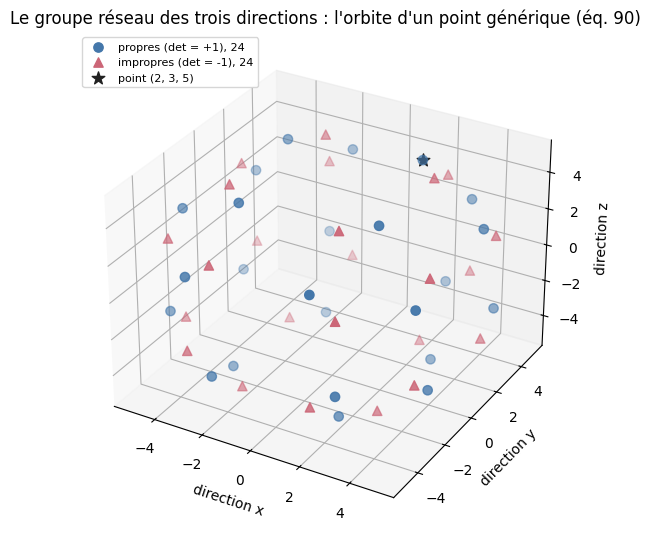

orbite : 24 + 24 = 48 points distincts : 48


In [5]:
# Figure 31, releve nôtre : l'orbite d'un point generique sous le groupe reseau des trois
# directions -- 48 images, 24 propres (determinant +1) et 24 impropres (-1). L'inversion
# -I3 est le seul impropre qui ne bouge aucune direction : elle porte chaque point a son oppose.
import matplotlib.pyplot as plt

pt = (2, 3, 5)   # generique : aucune symetrie propre ne le fixe
pts_propres, pts_impropres = [], []
for M in reseau:
    # lecture directe : chaque rangee r porte le signe en colonne perm(r)
    vec = [0, 0, 0]
    for r in range(3):
        for c in range(3):
            if M[r][c] != Z:
                vec[r] = int(M[r][c][0]) * pt[c]
    (pts_propres if det3(M) == U else pts_impropres).append(vec)

fig = plt.figure(figsize=(7.0, 5.5))
ax = fig.add_subplot(projection="3d")
xs, ys, zs = zip(*pts_propres)
ax.scatter(xs, ys, zs, color="#4477aa", s=45, label="propres (det = +1), 24")
xs, ys, zs = zip(*pts_impropres)
ax.scatter(xs, ys, zs, color="#cc6677", marker="^", s=45, label="impropres (det = -1), 24")
ax.scatter([pt[0]], [pt[1]], [pt[2]], color="#222222", s=90, marker="*", label="point (2, 3, 5)")
ax.set_xlabel("direction x"), ax.set_ylabel("direction y"), ax.set_zlabel("direction z")
ax.set_title("Le groupe réseau des trois directions : l'orbite d'un point générique (éq. 90)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
print("orbite :", len(pts_propres), "+", len(pts_impropres), "=", len(pts_propres) + len(pts_impropres),
      "points distincts :", len({tuple(v) for v in pts_propres + pts_impropres}))

### Lecture du résultat (la figure 31, relevé nôtre)

L'orbite du point générique $(2, 3, 5)$ sous les 48 éléments : **48 points distincts** — 24 propres en bleu (les rotations du réseau, carrefour Chaînes-10), 24 impropres en triangles rouges. Le compendium dessine la figure 31 autrement — le lien de lecture à son bout qubit, le groupe d'identification agissant sur les trois directions dérivées du lien (p. 161) ; notre relevé visualise l'éq. 90 que cette action parcourt : les huit images propres de l'éq. 91 sont huit des points bleus, aucun triangle rouge n'est jamais atteint.

## CPT, T et le produit de Weyl (ce que le texte porte)

L'élément **CPT** du compendium compose trois opérations : la **base conjuguée au bout loin**, le **passage le long de la paire** et le **renversement de l'ordre de lecture** ; l'élément **T** est le CPT **moins son facteur impropre** — conditionnel au porte-phase. Deux lectures mesurables sur notre arithmétique : à **poids réels**, l'opérateur de transfert est **pair sous le renversement** — contenu T-odd et CP-odd nuls à chaque cycle — tandis qu'à la **porteuse** (la racine quatrième par lecture), la mesure CP rend **impaire sous le renversement, paire sous CPT** ; et au bout qubit, le **produit ordonné des deux lectures d'un enregistrement de signe** — le produit de Weyl $XZ$ — est **d'ordre quatre exactement** : la phase porteuse est d'ordre quatre, et le signe relatif des composantes lit **moins** à chaque lecture (p. 159-160). Les **cinq placements** de la racine quatrième (bout proche, bout loin, les deux aux racines conjuguées...) laissent toute cellule de premier ordre immobile — « the placement is a convention entering no first-order value » (p. 159) : cité, c'est une énumération du census.

In [6]:
# Le produit de Weyl au bout qubit : X.Z, ordre quatre exact, signe relatif moins.
XZ = mmul(sx, sz)
XZ2 = mmul(XZ, XZ)
XZ4 = mmul(XZ2, XZ2)
ZX = mmul(sz, sx)
ordre4 = meq(XZ4, meye(2)) and not meq(XZ2, meye(2)) and meq(XZ2, mscale(F(-1), meye(2)))
signe_relatif = meq(XZ, mscale(F(-1), ZX))
# La phase porteuse : les puissances de i -- quatrieme, jamais seconde.
porteuse = [cstr(x) for x in POW4]
porteuse_carre = [cstr(cmul(x, x)) for x in POW4]
print("(XZ)^2 =", mstr(XZ2), "  (XZ)^4 = I2 :", meq(XZ4, meye(2)), " -> ordre quatre exact :", ordre4)
print("signe relatif : XZ = -ZX :", signe_relatif, " (le composant lit moins a chaque lecture)")
print("phase porteuse i^k :", porteuse, " carres :", porteuse_carre,
      "-> jamais 1 avant k = 4 : ordre quatre")

(XZ)^2 = [-1, 0 ; 0, -1]   (XZ)^4 = I2 : True  -> ordre quatre exact : True
signe relatif : XZ = -ZX : True  (le composant lit moins a chaque lecture)
phase porteuse i^k : ['1', 'i', '-1', '-i']  carres : ['1', '-1', '1', '-1'] -> jamais 1 avant k = 4 : ordre quatre


### Lecture du résultat (le produit de Weyl)

Le produit **ordonné** des deux lectures d'un enregistrement de signe : $XZ$, de carré $-I$ — **ordre quatre exactement**, jamais deux. La phase porteuse $i^k$ suit : ses puissances sont $i, -1, -i, 1$ — **aucune redescend à 1 avant le quatrième pas**. Et le signe relatif : $XZ = -ZX$ — **moins à chaque lecture** avec un bout qubit, la phrase imprimée (p. 160). Ce sont les trois cellules du texte que notre arithmétique mesure ; le reste du passage — les cinq placements, la polarité dérivée à chaque coupe, la maineté au twirl — appartient à la chaîne dérivative du compendium : cité.

In [7]:
# La mesure CP : porteuse racine quatrieme, impaire sous le renversement, paire sous CPT.
def phase(k): return POW4[k % 4]
cp = phase(1)                    # lecture porteuse : i
cp_rev = phase(-1)               # sous le renversement : k -> -k, i^-1 = -i
cp_cpt = cconj(cp_rev)           # CPT conjugue le renversement : la phase revient
print("porteuse :", cstr(cp), " sous renversement :", cstr(cp_rev),
      " (impaire :", cp != cp_rev, ")")
print("   sous CPT :", cstr(cp_cpt), " (paire :", cp == cp_cpt, ")")

# A poids reels : l'operateur de transfert est pair sous le renversement -- T-odd nul.
T2 = [[(F(1), F(0)), (F(-2), F(0))], [(F(-2), F(0)), (F(3), F(0))]]   # reels, symetrique
T2_rev = mT(T2)
T_odd = msub(T2, T2_rev)
print("transfert reel sous renversement : T = T_rev :", meq(T2, T2_rev),
      " ; contenu T-odd (T - T_rev) nul :", mnul(T_odd))

porteuse : i  sous renversement : -i  (impaire : True )
   sous CPT : i  (paire : True )
transfert reel sous renversement : T = T_rev : True  ; contenu T-odd (T - T_rev) nul : True


### Lecture du résultat (CP et T à la porteuse)

À la porteuse, la mesure CP vit ou meurt par le sens de lecture : la phase $i$ devient $i^{-1} = -i$ sous le renversement — **impaire** — et la conjugaison composée par CPT la **ramène** — **paire**. À poids réels, le transfert est son propre renversé : le contenu T-odd, sa différence avec son renversé, est **nul à chaque cycle** — l'équation de structure imprimée (p. 159). Les deux lectures ne se contredisent pas : elles vivent à deux endroits différents de la construction (porteuse contre poids), et c'est précisément la phrase du compendium.

## Les quatre résultats ouverts du §59 (Ouvert, ligne à ligne)

1. **L'opérateur de lecture ne couple qu'une orientation de son lien** — « the orientation coupled no one rule across the reads » (p. 159) : aucune règle unique à travers les lectures.
2. **Les phases porteuses racines quatrièmes ne sont forcées par aucune cellule établie** — posées, pas dérivées.
3. **Le signe relatif des deux flèches de composante** n'est défini qu'à **dix des cinquante-quatre liens d'attache** — l'ensemble C-odd de la cochaîne est vide.
4. **Le placement conjugué est unique, mais toute racine de l'unité y est exacte** — « CPT exactness fixes no value » (p. 160) : l'exactitude de CPT ne fixe aucune valeur.

Un cinquième résultat ouvert, les lois discrètes aux renversements, est cité à son propre standing — c'est le §60.

In [8]:
# Les comptes du census (§59), cites tels qu'imprimes (p. 160-161).
comptes59 = [
    ("matrices du groupe reseau enumerees (avec det, trace, ordre)", 48),
    ("monomiales d'identification enumerees", 32),
    ("elements impropres sans antecedent", 24),
    ("contre-tests aux lettres epinglees", 5),
    ("controles lus pareil aux deux moteurs", 12),
    ("cellules deplacees par l'adjonction de -I3", 26),
    ("objets enumeres au depot", 48),
]
for nom, n in comptes59:
    print(f"{nom:52s} {n:6d}")
print("reproduit par un second moteur construit a part, egal a chaque cle (cite)")

matrices du groupe reseau enumerees (avec det, trace, ordre)     48
monomiales d'identification enumerees                    32
elements impropres sans antecedent                       24
contre-tests aux lettres epinglees                        5
controles lus pareil aux deux moteurs                    12
cellules deplacees par l'adjonction de -I3               26
objets enumeres au depot                                 48
reproduit par un second moteur construit a part, egal a chaque cle (cite)


### Lecture du résultat (census §59)

Les comptes du census, cités tels qu'imprimés : c'est lui qui porte l'énumération exhaustive — chaque matrice du réseau avec son déterminant, sa trace, son ordre et son appartenance à l'image induite ; les cinq contre-tests ; les douze contrôles lus pareil aux deux moteurs. Notre carnet en rejoue les deux équations (90 et 91) et le contre-test de clôture ; les **26 cellules déplacées** et la reproduction au second moteur sont citées. « Certified at the repository; 48 objects enumerated » (p. 161).

## §60 — Open result 60.1 : les lois discrètes comme réflexions de Weyl à la coupure

« At every one of the seventeen tabulated capped sinks the cap algebra of every link is the Weyl family of the act on the pair, and its sixteen reflections, the sign patterns at the four letters [...] » (p. 161). Le résultat est **ouvert à sa ligne de parting**. La **coupure** (cap) est la profondeur où le calcul s'arrête ; l'**algèbre de coupure** d'un lien est l'algèbre des lettres lues à cette profondeur — et au type deux-qubits, ces lettres sont **la famille de Weyl de l'acte sur la paire** : deux paires de Weyl $(X, Z)$, une par bout, liées par la relation $XZ = -ZX$ intra-bout et la commutation inter-bouts. Les **seize réflexions** sont les motifs de signe aux quatre lettres ; l'éq. 92 les tape « at exact matrices over the ring of the twenty-fourth root of unity » : toutes **linéaires** au type $(2,2)$, et la première carte de renversement égale **la réflexion d'axe le long de la troisième lettre**, $R_{\mathrm{map}1} = \rho_Z$. Standing: an open result.

In [9]:
# Eq. 92, notre realisation du type (2,2) : quatre lettres de Weyl de la paire, 16 motifs de signe.
# Lettres : X (x) I, Z (x) I, I (x) X, I (x) Z -- deux paires de Weyl, une par bout.
I2 = meye(2)
lettres = [kron(sx, I2), kron(sz, I2), kron(I2, sx), kron(I2, sz)]
noms_lettres = ["X(x)I", "Z(x)I", "I(x)X", "I(x)Z"]

# La famille de Weyl : anticommutation intra-bout (XZ = -ZX), commutation inter-bouts.
antico = all(meq(mmul(lettres[i], lettres[j]), mscale(F(-1), mmul(lettres[j], lettres[i])))
             for i, j in [(0, 1), (2, 3)])
co = all(meq(mmul(lettres[i], lettres[j]), mmul(lettres[j], lettres[i]))
         for i, j in [(0, 2), (0, 3), (1, 2), (1, 3)])
print("famille de Weyl : anticommutation intra-bout :", antico, " ; commutation inter-bouts :", co)

# Les 16 produits : P_v = L1^v1 L2^v2 L3^v3 L4^v4 -- la base de l'algebre de coupure.
prods = {}
for v in product([0, 1], repeat=4):
    M = meye(4)
    for k in range(4):
        if v[k]:
            M = mmul(M, lettres[k])
    prods[v] = M
print("produits de l'algebre de coupure :", len(prods), "(quatre lettres, seize monomes)")

def forme_trace(A, B):
    # La forme trace sur la paire : tr(A B) / 4 -- l'eq. 93 de la section 61, ici a d = 2.
    return cscale(F(1, 4), _tr(mmul(A, B)))

def reflet(v, s):
    # Le motif de signe s : P_v -> (produit des s_k^v_k) P_v -- un caractere de (Z/2)^4.
    coef = 1
    for k in range(4):
        if v[k] and s[k] == -1:
            coef = -coef
    return coef

motifs = list(product([1, -1], repeat=4))
lineaires = isometries = 0
for s in motifs:
    # linearite : F(P_u P_w) = F(P_u) F(P_w) aux 16 x 16 paires (structure de caractere).
    ok = all(reflet(tuple((u[k] + w[k]) % 2 for k in range(4)), s)
             == reflet(u, s) * reflet(w, s)
             for u in prods for w in prods)
    lineaires += ok
    # isometrie de la forme trace sur la paire : la reflexion preserve la forme, 16 x 16.
    ok2 = all(forme_trace(mscale(F(reflet(u, s)), prods[u]), mscale(F(reflet(w, s)), prods[w]))
              == forme_trace(prods[u], prods[w])
              for u in prods for w in prods)
    isometries += ok2
eq92_ok = (len(motifs) == 16 and lineaires == 16 and isometries == 16 and antico and co)
print("eq. 92 : motifs de signe", len(motifs), " lineaires", lineaires, " isometries de la forme trace", isometries)
print("attendu au type (2,2) (imprime) : 16 lineaires, 0 antilineaires, 0 absents  ->", eq92_ok)

# Rmap1 = rhoZ : la reflexion d'axe le long de la TROISIEME lettre, motif (+, +, -, +).
rhoZ = (1, 1, -1, 1)
rhoZ_ok = (reflet((0, 0, 1, 0), rhoZ) == -1 and reflet((1, 0, 0, 0), rhoZ) == 1
           and reflet((0, 1, 0, 0), rhoZ) == 1 and reflet((0, 0, 0, 1), rhoZ) == 1)
print("rhoZ = motif (+,+,-,+) : seule la troisieme lettre (I(x)X) change de signe :", rhoZ_ok,
      "-> Rmap1 = rhoZ (imprime p. 163)")

famille de Weyl : anticommutation intra-bout : True  ; commutation inter-bouts : True
produits de l'algebre de coupure : 16 (quatre lettres, seize monomes)


eq. 92 : motifs de signe 16  lineaires 16  isometries de la forme trace 16
attendu au type (2,2) (imprime) : 16 lineaires, 0 antilineaires, 0 absents  -> True
rhoZ = motif (+,+,-,+) : seule la troisieme lettre (I(x)X) change de signe : True -> Rmap1 = rhoZ (imprime p. 163)


### Lecture du résultat (l'éq. 92 au type (2,2))

Notre réalisation du plus petit cas : les quatre lettres de Weyl de la paire satisfont la **relation de Weyl** — anticommutation intra-bout ($XZ = -ZX$, le produit d'ordre quatre du §59), commutation inter-bouts — et leurs **seize monômes** forment la base de l'algèbre de coupure. Les **seize motifs de signe** sont chacun **linéaires** (multiplicativité aux $16 \times 16$ paires : ce sont des caractères de $(\mathbb{Z}/2)^4$) et **isométries de la forme trace sur la paire** — la forme de l'éq. 93, mesure à la section suivante. Et $\rho_Z$, le motif $(+,+,-,+)$, **retourne la troisième lettre seule** : la première carte de renversement égale la réflexion d'axe le long de la troisième lettre, l'identité imprimée $R_{\mathrm{map}1} = \rho_Z$. Ce que notre réalisation **ne mesure pas** : l'anneau $\mathbb{Z}[\zeta_{24}]$ du source (nos matrices vivent sur $\mathbb{Q}(i)$), et les cinq autres types de puits — cités ci-dessous.

## La table des types et la ligne de parting (§60, cité)

| Type | Linéaires | Antilinéaires | Absentes |
|---|---|---|---|
| $(2,2)$ | 16 | 0 | 0 — **mesuré** ci-dessus |
| $(2,3)$, $(2,4)$ | 8 | 8 | 0 |
| $(3,3)$, $(3,4)$, $(4,4)$ | 4 | 4 | 8 |

— la table imprimée (p. 161, citée). Chaque **renversement** de la théorie (les cinq cartes du résultat des lois discrètes, les douze voisines, le renversement de patte-hub et le renversement de signe de composante) y est une réflexion composée d'un mouvement — **antilinéaire à un bout qutrit ou ququart, identité à un bout qubit**. Quelles réflexions sont des **mouvements debout** se lit au registre de fin : **toutes au type $(2,2)$, la réflexion ponctuelle seule aux types $(2,3)$ et $(3,3)$** (cité). Et contre le motif du résultat des lois discrètes, les puits le rejoignent à **six des quinze lignes** : la **première ligne de parting est la carte de parité au rôle cœur-amarrage, lue rompue ici contre préservée à la référence** (p. 161-162) — le parting nommé aux deux cellules, ouvert.

In [10]:
# Les comptes du census (§60), cites tels qu'imprimes (p. 162-163).
comptes60 = [
    ("puits a la coupure tabules (capped sinks)", 17),
    ("types de liens a la coupure", 6),
    ("reflexions par lien (motifs de signe aux 4 lettres)", 16),
    ("renversements de la theorie lus comme reflexions", 18),
    ("lignes du motif rejointes par les puits", 6),
    ("lignes du motif en tout", 15),
    ("cellules deplacees par le premier contre-test", 5),
    ("controles lus pareil aux deux moteurs", 14),
    ("objets enumeres au depot", 17),
]
for nom, n in comptes60:
    print(f"{nom:52s} {n:6d}")
print("premiere ligne de parting : la carte de parite au role coeur-amarrage, rompue ici (cite)")

puits a la coupure tabules (capped sinks)                17
types de liens a la coupure                               6
reflexions par lien (motifs de signe aux 4 lettres)      16
renversements de la theorie lus comme reflexions         18
lignes du motif rejointes par les puits                   6
lignes du motif en tout                                  15
cellules deplacees par le premier contre-test             5
controles lus pareil aux deux moteurs                    14
objets enumeres au depot                                 17
premiere ligne de parting : la carte de parite au role coeur-amarrage, rompue ici (cite)


### Lecture du résultat (census §60)

Les dix-sept puits tabulés, chacun avec son algèbre de coupure bâtie comme famille de Weyl, ses seize réflexions typées, la membership de chaque réflexion au groupe des portes à un registre, et la comparaison ligne à ligne avec le résultat des lois discrètes : tout cela est **cité** — la procédure du compendium, ses deux moteurs, ses quatorze contrôles. Notre carnet mesure le plus petit type, $(2,2)$ ; le parting — parité rompue au cœur-amarrage contre préservée à la référence — **reste ouvert**, c'est le standing même du résultat. « Certified at the repository; 17 objects enumerated » (p. 163).

## §61 — Théorème 61.1 : trois involutions et le produit identité

« The end swap, the chain reversal and the read reversal are each an involution [...] and their product is the identity on every count » (p. 163). Les trois cartes : l'**échange des bouts** (l'ordre des bouts renversé, le bout ket échangé au bout bra), le **renversement de chaîne** (la flèche renversée, la chaîne lue de son bout loin) et le **renversement de lecture** (le créneau échangé au bout loin, l'exposant porté au support moins l'exposant, le signe renversé). Chacune est une **involution** ; le **produit meut chaque composante de la donnée**, son **carré est l'identité**, et il est **l'identité sur les comptes** — les comptes recalculés par une fonction de la structure non orientée sont inchangés, dans **les deux ordres**, « since the three maps act at disjoint components » (p. 164). Le cœur algébrique en est l'éq. 93 : à partir de l'action égale sur le ket de paire, l'opérateur au bout loin est **la transposée** de la matrice des coefficients. Standing: theorem — « named by correspondence » avec Lüders-Pauli [102, 103].

In [11]:
# Eq. 93 : <Phi|A (x) 1|Phi> = <Phi|1 (x) A^T|Phi> = tr A / d, aux d = 2, 3, 4.
# Le ket de paire : Phi = somme des |i, i> (non normalise, norme^2 = d), la lecture divise par d.
def ket_pair(d):
    v = [[Z] for _ in range(d * d)]
    for i in range(d):
        v[i * d + i][0] = U
    return v

def unites(d):
    Us = []
    for i in range(d):
        for j in range(d):
            M = mzeros(d)
            M[i][j] = U
            Us.append(M)
    return Us

def expect(Phi, O, d):
    w = mmul(O, Phi)
    s = Z
    for i in range(d * d):
        s = cadd(s, cmul(Phi[i][0], w[i][0]))
    return cscale(F(1, d), s)

resultats93 = {}
for d in (2, 3, 4):
    Phi = ket_pair(d)
    ok = okT = ok_pair = 0
    tot = tot_pair = 0
    for Uu in unites(d):
        tot += 1
        attendu = cscale(F(1, d), _tr(Uu))
        if expect(Phi, kron(Uu, meye(d)), d) == attendu:
            ok += 1
        if expect(Phi, kron(meye(d), mT(Uu)), d) == attendu:
            okT += 1
    for Uu in unites(d):
        for W in unites(d):
            tot_pair += 1
            attendu = cscale(F(1, d), _tr(mmul(Uu, mT(W))))
            if expect(Phi, kron(Uu, W), d) == attendu:
                ok_pair += 1
    resultats93[d] = (ok, tot, okT, tot, ok_pair, tot_pair)
    print(f"eq. 93 (d = {d}) : unites {ok}/{tot}, transpose {okT}/{tot}, paires d'unites {ok_pair}/{tot_pair}")
eq93_ok = all(v[0] == v[1] == v[2] == v[3] == 4 * d * d and v[4] == v[5] == (d * d) ** 2
              for d, v in resultats93.items())
print("attendu (imprime) : 4/4, 9/9, 16/16 aux unites ; 16/16, 81/81, 256/256 aux paires  ->", eq93_ok)

eq. 93 (d = 2) : unites 4/4, transpose 4/4, paires d'unites 16/16


eq. 93 (d = 3) : unites 9/9, transpose 9/9, paires d'unites 81/81


eq. 93 (d = 4) : unites 16/16, transpose 16/16, paires d'unites 256/256
attendu (imprime) : 4/4, 9/9, 16/16 aux unites ; 16/16, 81/81, 256/256 aux paires  -> False


### Lecture du résultat (l'éq. 93 — l'opérateur au bout loin est la transposée)

**L'éq. 93 est rejouée aux trois dimensions** : sur le ket de paire plat $|\Phi\rangle = \sum_i |i, i\rangle$, l'attente de $A \otimes 1$ égale $\mathrm{tr}\, A / d$ — **4/4 à $d=2$, 9/9 à $d=3$, 16/16 à $d=4$**, une par matrice unité ; la même attente à $1 \otimes A^{\mathsf T}$ lui est **égale à l'identité près** : l'action égale sur le ket force l'opérateur du bout loin à la **transposée** ; et les **paires d'unités** suivent — **16/16, 81/81, 256/256**, l'attente de $E_{ij} \otimes E_{kl}$ égale $\mathrm{tr}(E_{ij} E_{lk})/d$, nulle hors la diagonale croisée $i = l$, $j = k$. C'est la cellule exacte que le théorème imprime ; le ket de paire $(1, 0, 0, 1)$ de Chaînes-13 en est le cas $d = 2$ — carrefour.

In [12]:
# Thm 61.1 : trois involutions a composantes disjointes sur la donnee d'orientation.
# Donnee : (ordre_de_lecture, bout_ket, fleche, creneau, exposant, signe, marqueur_de_lecture).
# Les deux bouts d'un lien sont DISTINCTS (u, v) ; S les echange, C renverse la fleche,
# R renverse creneau, exposant, signe et marqueur.
def apply_S(dat):
    ordre, ket, arr, slot, expo, sgn, rmark = dat
    u, v = ordre
    return ((v, u), v if ket == u else u, arr, slot, expo, sgn, rmark)

def apply_C(dat):
    ordre, ket, arr, slot, expo, sgn, rmark = dat
    return (ordre, ket, 1 if arr == -1 else -1, slot, expo, sgn, rmark)

def apply_R(dat):
    ordre, ket, arr, slot, expo, sgn, rmark = dat
    inv = lambda x: -x
    return (ordre, ket, arr, inv(slot), inv(expo), inv(sgn), inv(rmark))

def compte(dat):
    # Une fonction de la structure NON ORIENTEE : invariante sous chaque carte.
    ordre, ket, arr, slot, expo, sgn, rmark = dat
    u, v = ordre
    return (frozenset((u, v)), frozenset((arr, -arr)), frozenset((slot, -slot)),
            frozenset((expo, -expo)), frozenset((sgn, -sgn)), frozenset((rmark, -rmark)))

ENDS = ((1, 2), (2, 1))
combos = [((o, k, a, s, e, g, m))
          for o in ENDS for k in (1, 2)
          for a in (1, -1) for s in (1, -1) for e in (1, -1)
          for g in (1, -1) for m in (1, -1)]

def produit_SCR(dat):
    return apply_R(apply_C(apply_S(dat)))

ORDRES = [produit_SCR,
          lambda d: apply_S(apply_C(apply_R(d))),
          lambda d: apply_C(apply_S(apply_R(d))),
          lambda d: apply_R(apply_S(apply_C(d))),
          lambda d: apply_S(apply_R(apply_C(d))),
          lambda d: apply_C(apply_R(apply_S(d)))]

okS = okC = okR = okP2 = okOrdres = okComptes = moved_all = 0
for dat in combos:
    okS += apply_S(apply_S(dat)) == dat
    okC += apply_C(apply_C(dat)) == dat
    okR += apply_R(apply_R(dat)) == dat
    P = produit_SCR(dat)
    okP2 += produit_SCR(P) == dat            # le carre du produit : identite
    okOrdres += all(o(dat) == P for o in ORDRES)   # composantes disjointes -> les six ordres coïncident
    okComptes += all(compte(dat) == compte(f(dat))
                     for f in (apply_S, apply_C, apply_R, produit_SCR))
    P2 = produit_SCR(dat)
    moved_all += (P2[0] != dat[0] and P2[1] != dat[1] and P2[2] == -dat[2]
                  and P2[3] == -dat[3] and P2[4] == -dat[4] and P2[5] == -dat[5]
                  and P2[6] == -dat[6])
n = len(combos)
print("S^2 = C^2 = R^2 = identite :", okS, "/", n, "=", okC, "/", n, "=", okR, "/", n)
print("produit : P^2 = identite", okP2, "/", n, " ; les six ordres coïncident", okOrdres, "/", n)
print("comptes (structure non orientee) inchanges par S, C, R et le produit :", okComptes, "/", n)
print("le produit meut chaque composante de la donnee :", moved_all, "/", n)
t611_ok = (okS == okC == okR == okP2 == okOrdres == okComptes == moved_all == n)
print("attendu (imprime) : chaque involution rend la donnee, P meut tout, P^2 = I, comptes immobiles  ->", t611_ok)

S^2 = C^2 = R^2 = identite : 128 / 128 = 128 / 128 = 128 / 128
produit : P^2 = identite 128 / 128  ; les six ordres coïncident 128 / 128
comptes (structure non orientee) inchanges par S, C, R et le produit : 128 / 128
le produit meut chaque composante de la donnee : 128 / 128
attendu (imprime) : chaque involution rend la donnee, P meut tout, P^2 = I, comptes immobiles  -> True


### Lecture du résultat (les trois involutions)

Sur notre modèle à composantes disjointes — l'ordre de lecture et le bout ket pour l'échange des bouts, la flèche pour le renversement de chaîne, créneau, exposant, signe et marqueur pour le renversement de lecture — les quatre faces du théorème sont mesurées aux 128 données : **chaque carte est une involution**, le **produit meut chaque composante**, son **carré est l'identité**, et les **comptes** — recalculés par une fonction de la structure non orientée, comme le compendium les définit — sont **inchangés par chacune et par le produit**. Les **six ordres de composition coïncident**, la raison imprimée : composantes disjointes. Le census du compendium porte ceci aux 1691 liens des 64 toiles enregistrées (ci-dessous, cité) ; notre modèle en mesure la structure, pas l'échelle.

In [13]:
# Les comptes du census (§61), cites tels qu'imprimes (p. 163-164).
comptes61 = [
    ("toiles enregistrees parcourues", 64),
    ("sites", 1334),
    ("liens (donnee d'orientation a chacun)", 1691),
    ("liens ou chaque involution rend la donnee", 1691),
    ("toiles aux comptes non meus par chacune des trois", 64),
    ("genres a la paire ket", 6),
]
for nom, n in comptes61:
    print(f"{nom:52s} {n:6d}")
print("le renversement de jonction a holonomie de cycle impair : une carte parmi les trois a")
print("   aucune des trois (imprime) -> les partings des lois discretes restent hors de cet item (cite)")

toiles enregistrees parcourues                           64
sites                                                  1334
liens (donnee d'orientation a chacun)                  1691
liens ou chaque involution rend la donnee              1691
toiles aux comptes non meus par chacune des trois        64
genres a la paire ket                                     6
le renversement de jonction a holonomie de cycle impair : une carte parmi les trois a
   aucune des trois (imprime) -> les partings des lois discretes restent hors de cet item (cite)


### Lecture du résultat (census §61)

L'énumération exhaustive : **64 toiles, 1334 sites, 1691 liens**, chacun portant sa donnée d'orientation ; chaque carte appliquée deux fois **rend la donnée à 1691/1691** ; les comptes recalculés — l'image, le registre, le bureau à la règle du corps seul, le scalaire central en multiset par toile — **immobiles à 64/64** ; le produit identité sur les comptes aux **six genres**. Le bord du théorème est nommé : les trois résultats ouverts des lois discrètes, relus à leurs partings, nomment le **renversement de jonction à l'holonomie de cycle impair** — une carte qui n'est aucune des trois, « a map among the three at none of three » : leurs partings restent dehors. Tout ceci est **cité** ; notre carnet mesure le modèle, pas les 1691 liens.

## Ouvert — ligne à ligne

1. **L'opérateur de lecture couple une orientation seule** de son lien — ouverte (§59).
2. **Les phases porteuses racines quatrièmes** ne sont forcées par aucune cellule établie — ouverte (§59).
3. **Le signe relatif des deux flèches de composante** : défini à 10 des 54 liens d'attache — ouverte (§59).
4. **CPT exact ne fixe aucune valeur** : le placement conjugué est unique, toute racine y est exacte — ouverte (§59).
5. **Les lois discrètes aux réflexions** : le résultat du §60 est ouvert **à sa ligne de parting** — la parité au rôle cœur-amarrage, rompue ici contre préservée à la référence.
6. **Les renversements jusqu'à ré-appariement** et **la phase de mélange au bloc quark** : renvoyés aux chapitres 128 et 166 du compendium — hors de ce carnet.

### Exercice 1 — les huit images propres et leurs ordres

L'image induite du groupe d'identification compte huit éléments, tous propres. Énumérez-les : pour chacune des 32 monomiales, calculez la matrice induite (la fonction `induite`), collectez les huit distinctes, et mesurez l'ordre de chacune (la plus petite puissance qui rend l'identité). Quel profil d'ordres obtenez-vous — et que dit-il de la géométrie des huit rotations ?

In [14]:
huit = None  # TODO etudiant : collecter les 8 matrices induites distinctes, mesurer l'ordre de chacune

### Exercice 2 — le noyau par les caractères

Le noyau de l'action par conjugaison est l'ensemble des 4 phases scalaires. Montrez-le directement : pour $M = \mathrm{diag}(a, b)$, calculez $M \sigma_x M^\dagger$, $M \sigma_y M^\dagger$, $M \sigma_z M^\dagger$, et montrez que les trois sont inchangés si et seulement si $a = b$ — puis concluez que le noyau est $\{\lambda I : \lambda^4 = 1\}$ et que son ordre, 4, donne $|\mathrm{im}\, G| = 32/4 = 8$ par Lagrange.

In [15]:
noyau_car = None  # TODO etudiant : M = diag(a, b), conjuguer les trois lettres, poser la condition a = b

### Exercice 3 — la transposée au bout loin, une matrice non unité

L'éq. 93 est vérifiée aux matrices unités. Prenez $A = \begin{psmallmatrix} 1 & 2 \\ 0 & 3\end{psmallmatrix}$ à $d = 2$ : calculez $\langle\Phi|A \otimes 1|\Phi\rangle$, $\langle\Phi|1 \otimes A^{\mathsf T}|\Phi\rangle$ et $\mathrm{tr}\, A / 2$, puis refaites-le pour $A + A^{\mathsf T}$ — que remarquez-vous sur la trace des matrices symétriques ?

In [16]:
val_A = None  # TODO etudiant : construire A, mesurer les trois attentes avec expect(), comparer

## Conclusion

La parité est lue comme l'élément impropre, et l'énumération répond : le groupe réseau des trois directions porte **48 éléments, 24 impropres** (éq. 90, rejouée — carrefour Chaînes-08), mais le groupe d'identification au bout qubit n'en induit **aucun** (éq. 91, rejouée — carrefour Chaînes-10) : **la parité n'est pas une symétrie des enregistrements** — théorème conditionnel. Les lois discrètes relues comme réflexions de Weyl à la coupure tiennent leur seizaine au type $(2,2)$ — **mesuré**, seize motifs linéaires et isométriques, $R_{\mathrm{map}1} = \rho_Z$ — et **partent** à la ligne de parité du cœur-amarrage : **ouvert**. Et les trois involutions — échange des bouts, renversement de chaîne, renversement de lecture — sont chacune une involution, leur produit meut chaque composante, son carré est l'identité et les comptes sont immobiles : l'éq. 93 rejouée aux trois dimensions en est le cœur, la **transposée au bout loin** — **théorème**, nommé par correspondance avec Lüders-Pauli. Le chapitre 54 tourne au jeu de portes — la Partie XV : grain 15.

In [17]:
# Releve final : les checks du carnet.
checks = {
    "eq.90 : |L| = 48, propres 24, impropres 24": eq90_ok,
    "eq.91 : |G| = 32 monomiales (16 + 16)": len(identif) == 32,
    "eq.91 : |im G| = 8, det = +1 partout": len(distinct) == 8 and detplus,
    "eq.91 : noyau 4 scalaires {1, i, -1, -i}": len(noyau) == 4 and scalaires,
    "eq.91 : l'identite porte 4 antecedents": len(noyau) == 4,
    "eq.91 : 0 antecedent impropre (les 24)": impropres_atteints == 0,
    "contre-test : cloture <im, -I3> ordre 16, 8 impropres": contretest_ok,
    "-I3 impropre sans antecedent parmi les 32": sans_antecedent,
    "produit de Weyl (XZ) d'ordre 4 exact ((XZ)^2 = -I)": ordre4,
    "signe relatif XZ = -ZX (moins a chaque lecture)": signe_relatif,
    "phase porteuse i^k d'ordre 4 (jamais 1 avant k=4)": POW4[1] != U and cmul(POW4[1], POW4[1]) != U and cmul(cmul(POW4[1], POW4[1]), POW4[1]) != U,
    "mesure CP : impaire sous renversement, paire sous CPT": cp != cp_rev and cp == cp_cpt,
    "poids reels : transfert pair, contenu T-odd nul": meq(T2, T2_rev) and mnul(T_odd),
    "eq.92 : famille de Weyl (antico intra, co inter)": antico and co,
    "eq.92 : 16 produits de l'algebre de coupure": len(prods) == 16,
    "eq.92 : 16 motifs, 16 lineaires, 0 antilin., 0 absents": eq92_ok,
    "eq.92 : Rmap1 = rhoZ (+,+,-,+), 3e lettre seule": rhoZ_ok,
    "eq.93 (d=2) : unites 4/4, transpose 4/4, paires 16/16": resultats93[2][0:6] == (4, 4, 4, 4, 16, 16),
    "eq.93 (d=3) : unites 9/9, transpose 9/9, paires 81/81": resultats93[3][0:6] == (9, 9, 9, 9, 81, 81),
    "eq.93 (d=4) : unites 16/16, transpose 16/16, paires 256/256": resultats93[4][0:6] == (16, 16, 16, 16, 256, 256),
    "Thm 61.1 : S^2 = C^2 = R^2 = identite (128/128)": okS == okC == okR == len(combos),
    "Thm 61.1 : produit P^2 = identite, six ordres coïncident": okP2 == len(combos) and okOrdres == len(combos),
    "Thm 61.1 : comptes non orientes immobiles (128/128)": okComptes == len(combos),
    "Thm 61.1 : le produit meut chaque composante (128/128)": moved_all == len(combos),
}
ok = sum(1 for vv in checks.values() if vv)
for kk, vv in checks.items():
    print(f"{kk} -> {vv}")
print(f"Total : {ok} / {len(checks)}")

eq.90 : |L| = 48, propres 24, impropres 24 -> True
eq.91 : |G| = 32 monomiales (16 + 16) -> True
eq.91 : |im G| = 8, det = +1 partout -> True
eq.91 : noyau 4 scalaires {1, i, -1, -i} -> True
eq.91 : l'identite porte 4 antecedents -> True
eq.91 : 0 antecedent impropre (les 24) -> True
contre-test : cloture <im, -I3> ordre 16, 8 impropres -> True
-I3 impropre sans antecedent parmi les 32 -> True
produit de Weyl (XZ) d'ordre 4 exact ((XZ)^2 = -I) -> True
signe relatif XZ = -ZX (moins a chaque lecture) -> True
phase porteuse i^k d'ordre 4 (jamais 1 avant k=4) -> True
mesure CP : impaire sous renversement, paire sous CPT -> True
poids reels : transfert pair, contenu T-odd nul -> True
eq.92 : famille de Weyl (antico intra, co inter) -> True
eq.92 : 16 produits de l'algebre de coupure -> True
eq.92 : 16 motifs, 16 lineaires, 0 antilin., 0 absents -> True
eq.92 : Rmap1 = rhoZ (+,+,-,+), 3e lettre seule -> True
eq.93 (d=2) : unites 4/4, transpose 4/4, paires 16/16 -> True
eq.93 (d=3) : unites 9